# Song Title Prediction from 10-Second Humming and Whistling Recordings

# 1 Author

**Yu-Shan Lin**


# 2 Problem Formulation

In this project, the goal is to build a machine learning model that can recognize and predict the title of a song from a short audio recording of humming or whistling. The input consists of 10–20 second audio clips in `.wav` format, each labelled with the corresponding song title, and the task is formulated as a supervised multi-class classification problem.

This problem is meaningful and worth exploring because it reflects a real-world application used frequently in daily life. Many people often hear songs in public places, such as shopping malls or cafés, and want to find out the song title. Modern systems such as Google microphone-based music search already support similar functionality. If we can train a model that performs accurately, users would be able to identify songs they like without needing to ask others, who might not know the answer either.

However, this task is challenging, especially for beginners(like me.) without prior experience developing machine learning models. Audio data must first be transformed into numerical feature representations, such as vectors or spectrograms, before it can be used for model training. Additionally, humming recordings vary greatly between individuals in terms of rhythm, pitch stability, tempo, and noise levels. This variability makes classification difficult and increases the complexity of building a robust dataset and model. Even with short 10–20 second segments, distinguishing between many similar melodies is far from easy.


# 3 Methodology



I used two different approaches were used to train and evaluate models for audio song classification: an **MFCC-based** traditional machine learning model and a deep learning **CNN model**. The goal was to compare their performance and analyze how effectively each method learns from short humming or whistling recordings.


To train and evaluate the models, the dataset of audio recordings was divided into two subsets: a training set used to learn model parameters, and a validation set used to measure performance on unseen samples and prevent overfitting. I used an 80/20 split ratio to ensure that both sets are independent and consist of randomly selected samples.



Two different prediction pipelines were implemented and compared(**MFCC with SVM & CNN model**):

Traditional Machine Learning Baseline The first approach extracts MFCC (Mel-Frequency Cepstral Coefficients) features from each audio clip to convert raw audio into a compact numerical representation. These MFCC coefficients are then averaged over time to produce a fixed-length vector, which is used to train a Support Vector Machine (SVM) classifier. This baseline serves as a reference to understand how well a classical model performs without deep learning.



Deep Learning Approach (CNN model) The second approach transforms audio signals into Mel-spectrograms, which visually represent frequency information over time. These spectrograms are treated as input images to a Convolutional Neural Network (CNN), allowing the model to learn complex temporal-frequency patterns directly from data without manual feature engineering. The CNN is trained using categorical cross-entropy loss and the Adam optimizer.



Model performance was evaluated using classification accuracy on the validation set. The training process was monitored by tracking training and validation accuracy and loss curves, which helped assess model convergence and potential overfitting. The final comparison between SVM and CNN performance provides insight into the effectiveness of deep learning versus traditional feature-based approaches for audio song recognition.

# 4 Implemented ML prediction pipelines

Two different machine learning prediction pipelines were designed and implemented to recognize song titles from humming or whistling audio recordings. Each pipeline contains several processing stages, starting from raw audio input and ending with the final predicted song label output. Both pipelines share the same overall structure: Audio Input → Transformation Stage → Model Stage → Prediction Output, but differ in how features are represented and how the classification is performed.

## 4.1 Transformation stage

### **Pipeline A (MFCC feature extraction for SVM)**
Input:

The audio signal is first loaded and standardized to a consistent sample rate. Next, Mel-Frequency Cepstral Coefficients (MFCC) are extracted to convert the audio into a compact numerical feature representation that captures timbral and frequency characteristics important for distinguishing melodies.

Output:

A 20 × T MFCC matrix (20 coefficients × T time frames), which is averaged over the time axis into a 20-dimensional feature vector used as input for the SVM classifier.

Reason for choice:

MFCCs are widely used in speech and music classification tasks because they compress useful frequency patterns and reduce noise. This hand-crafted feature approach serves as a baseline to compare traditional machine learning against deep learning.

###**Pipeline B (Mel-spectrogram transformation for CNN)**
Input:

The audio is converted into a Mel-spectrogram, which visually represents how frequency content changes over time. The spectrogram is then normalized and resized so that it can be treated as an image for deep learning.

Output:

2D spectrogram image tensor.

Reason for choice:

CNNs perform strongly on image-like structures and can automatically learn complex temporal-frequency relationships without manual feature engineering. Spectrograms contain more detailed structure compared to MFCC and better support learning with deep neural networks.

## 4.2 Model stage

###**SVM Classifier**

In the first pipeline, a Support Vector Machine (SVM) is trained using time-averaged MFCC feature vectors. SVMs are effective for high-dimensional classification tasks and provide a strong baseline model for comparison. This approach tests how well traditional machine learning performs on audio data without deep learning.

###**Convolutional Neural Network (CNN)**

In the second pipeline, a CNN model is trained using Mel-spectrogram images as input. The CNN includes convolutional layers for feature extraction, max-pooling for downsampling, and fully connected layers for classification using a softmax output.

**Reason for choice:**

CNNs excel at recognizing spatial patterns and are commonly used in audio classification when data is represented as spectrograms. The model can learn descriptors directly from raw visualized frequency information.

## 4.3 Ensemble stage

I used an ensemble would require combining multiple different models. However, due to limited time and experience, I focused on testing two different models to see which one would achieve better accuracy and results. In my experiments, it was clear that the CNN performed better, reaching about 30% accuracy, while the SVM only achieved around 15%. Using an ensemble to combine both models might potentially improve the accuracy further, but it is evident that the CNN alone already outperforms the SVM by a significant margin.

# 5 Dataset

The dataset used in this project is derived from the MLEnd Hums and Whistles II Dataset, which contains short humming or whistling recordings paired with their corresponding song labels. The 400-sample subset was used. Each record is a 10–20 second .wav audio clip and includes a song title that serves as the classification label.


To prepare the dataset for model training, all audio files were first loaded into a pandas DataFrame containing the file path and associated label. This structure allows efficient exploration, transformation, and batch processing of audio data during both the MFCC-based and CNN-based pipelines.


A train/validation split was applied using an 80/20 ratio. This ensures that the training set is used solely for parameter learning while the validation set evaluates model performance on unseen examples. The split was performed randomly to keep both subsets independent and approximately IID, reducing the risk of biased evaluation.


Exploratory analysis was also conducted to understand the dataset. This included visualizing the number of samples per class, inspecting example audio waveforms, and plotting MFCC or Mel-spectrogram representations. These visualizations help verify that the dataset is suitable for both traditional and deep learning approaches.

One limitation of the dataset is its relatively small size (400 samples), which may restrict the generalization ability of the models.


# 6 Experiments and results

I compared two different machine learning approaches for predicting song titles from humming or whistling audio recordings:

1.   a traditional MFCC + SVM pipeline
2.   a deep learning CNN pipeline using Mel-spectrograms.



Both models were trained and evaluated using the same 80/20 train–validation split. Their performance was mainly measured using classification accuracy, together with visual inspection of accuracy/loss curves during training.

# 6.1 MFCC + SVM Baseline

### Set up

*   Input features: 20 MFCCs extracted from each audio clip (sample rate 22,050 Hz)
*   Feature preprocessing: MFCCs averaged over time into a 20-dimensional vector, then standardised
*   Model: Support Vector Machine with an RBF kernel and default hyperparameters
*   Data split: stratified 80/20 split (320 training, 80 validation samples)
*   Evaluation metric: validation accuracy and confusion matrix














### Results

The SVM achieved a validation accuracy of 16.25%. With 8 song classes, random guessing would give 12.5%, so the model performs only slightly better than chance.

*   MFCCs mainly capture timbre rather than melody, so they may not distinguish songs well when different people hum or whistle them
*   Averaging MFCCs over time removes the temporal structure, which is where most of the melodic information is
*   The 400-sample dataset is small given the high variation between participants

  ### Analysis

The SVM baseline serves as a useful reference, but the experiment shows that simple handcrafted features are insufficient for this task. The model struggles to learn robust patterns from humming recordings that vary widely in pitch, rhythm, and noise.

# 6.2 CNN on Mel-Spectrograms

  ### Set up

*   Input features: Mel-spectrograms generated from each audio file
*   CNN architecture: several convolution + pooling layers, followed by dense layers and softmax output
*   Loss function: categorical cross-entropy
*   Optimizer: Adam
*   Training monitoring: accuracy and loss curves

### Results

The CNN reached a training accuracy of about 86% after 20 epochs, while validation accuracy fluctuated between 12.5% and 28.75%. The best validation accuracy was 28.75% (epochs 7 and 12) and the final epoch reached 25%.

This is clearly better than the SVM baseline (16.25%) and random guessing (12.5%), suggesting that Mel-spectrograms preserve more of the frequency–time structure needed to recognise melodies.

### Analysis

The large gap between training (~86%) and validation (~25%) accuracy shows strong overfitting. Validation loss stopped improving after around epoch 9 and then increased, while training loss kept decreasing. This is expected given the small dataset and the size of the model (about 17.8 million parameters, most of them in the first dense layer).

The best validation accuracy (28.75%) should be interpreted with caution: it was selected as the maximum over 20 epochs on the same validation set, without a separate test set, so it is likely an optimistic estimate.

# 7 Conclusions

Two pipelines were compared for predicting song titles from humming and whistling recordings. The CNN on Mel-spectrograms (about 25–29% validation accuracy) clearly outperformed the MFCC + SVM baseline (16.25%), while both remained well below a level that would be useful in practice. With 8 classes, random guessing would achieve 12.5%.

The results suggest that representations which keep the temporal structure of the melody are more suitable for this task than time-averaged timbral features. However, the CNN overfitted strongly, and its accuracy varied by a few percentage points between runs due to random initialisation and non-deterministic GPU operations.

Several limitations affect these conclusions:

*   The dataset is small (400 samples), and only one train/validation split was used.
*   The reported best CNN accuracy was chosen on the validation set, so it is likely optimistic.
*   The split was random rather than grouped by participant, so recordings from the same person may appear in both sets.

Possible improvements include data augmentation (pitch shifting, time stretching), regularisation such as early stopping or a smaller dense layer, pitch-based features (e.g. chroma or pitch contours) that are less sensitive to individual voices, participant-grouped cross-validation, and using the larger 800-sample dataset.

# 8 References

Tools(help to debug and generate idea) : Chatgpt, Gemini

Reference : Slides and lab materials which from lectures and lab time.

# 9 Code of model

# MFCC + SVM

In [ ]:
!pip install -q librosa soundfile scikit-learn matplotlib seaborn numpy pandas tqdm

In [ ]:
!ls /content/dataset

S100_hum_2_Married.wav		  S19_whistle_1_Happy.wav
S100_whistle_2_Happy.wav	  S1_hum_2_Necessities.wav
S100_whistle_2_RememberMe.wav	  S1_hum_2_TryEverything.wav
S101_hum_1_Married.wav		  S1_whistle_1_NewYork.wav
S101_hum_2_Friend.wav		  S20_hum_2_RememberMe.wav
S103_hum_1_Necessities.wav	  S20_hum_4_Happy.wav
S103_hum_3_RememberMe.wav	  S20_hum_4_NewYork.wav
S104_hum_2_NewYork.wav		  S21_hum_1_TryEverything.wav
S104_whistle_1_Married.wav	  S21_whistle_1_Married.wav
S104_whistle_2_Necessities.wav	  S21_whistle_1_Necessities.wav
S105_whistle_2_Married.wav	  S21_whistle_1_RememberMe.wav
S105_whistle_2_Necessities.wav	  S22_whistle_1_Necessities.wav
S106_hum_2_Married.wav		  S22_whistle_2_NewYork.wav
S106_hum_2_RememberMe.wav	  S23_hum_2_Friend.wav
S107_whistle_2_Friend.wav	  S23_hum_2_NewYork.wav
S108_whistle_1_RememberMe.wav	  S24_hum_1_Feeling.wav
S108_whistle_2_Happy.wav	  S24_whistle_1_Married.wav
S109_hum_1_Married.wav		  S24_whistle_2_Happy.wav
S109_hum_1_TryEverything.wav	  S25_hum

In [ ]:
import os, glob

base = "/content/dataset"

audio_dir = base
print("audio_dir exists?", os.path.exists(audio_dir))

files = sorted(glob.glob(os.path.join(audio_dir, "*.wav")))
print("Number of wav files:", len(files))
print("Sample file list:")
for f in files[:10]:
    print(f)

audio_dir exists? True
Number of wav files: 400
Sample file list:
/content/dataset/S100_hum_2_Married.wav
/content/dataset/S100_whistle_2_Happy.wav
/content/dataset/S100_whistle_2_RememberMe.wav
/content/dataset/S101_hum_1_Married.wav
/content/dataset/S101_hum_2_Friend.wav
/content/dataset/S103_hum_1_Necessities.wav
/content/dataset/S103_hum_3_RememberMe.wav
/content/dataset/S104_hum_2_NewYork.wav
/content/dataset/S104_whistle_1_Married.wav
/content/dataset/S104_whistle_2_Necessities.wav


In [ ]:
import os, glob, pandas as pd

base = "/content/dataset"
files = sorted(glob.glob(os.path.join(base, "*.wav")))

data = []
for f in files:
    filename = os.path.basename(f)
    song_label = filename.split("_")[-1].replace(".wav","")
    data.append((f, song_label))

df = pd.DataFrame(data, columns=["file_path", "label"])
print(df.head())

                                        file_path       label
0         /content/dataset/S100_hum_2_Married.wav     Married
1       /content/dataset/S100_whistle_2_Happy.wav       Happy
2  /content/dataset/S100_whistle_2_RememberMe.wav  RememberMe
3         /content/dataset/S101_hum_1_Married.wav     Married
4          /content/dataset/S101_hum_2_Friend.wav      Friend


In [ ]:
import librosa
import numpy as np


y, sr = librosa.load(df.file_path[0], sr=None)
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
print(mfcc.shape)  # (n_mfcc, frames)

(13, 2076)


In [ ]:
features = []
labels = []

for path, label in zip(df.file_path, df.label):
    y, sr = librosa.load(path, sr=22050)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    mfcc_mean = np.mean(mfcc, axis=1)
    features.append(mfcc_mean)
    labels.append(label)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

Feature shape: (400, 20)
Label shape: (400,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (320, 20) Test: (80, 20)


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

svm = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
svm.fit(X_train, y_train)

print("Training completed!")

Training completed!


Accuracy: 0.1625


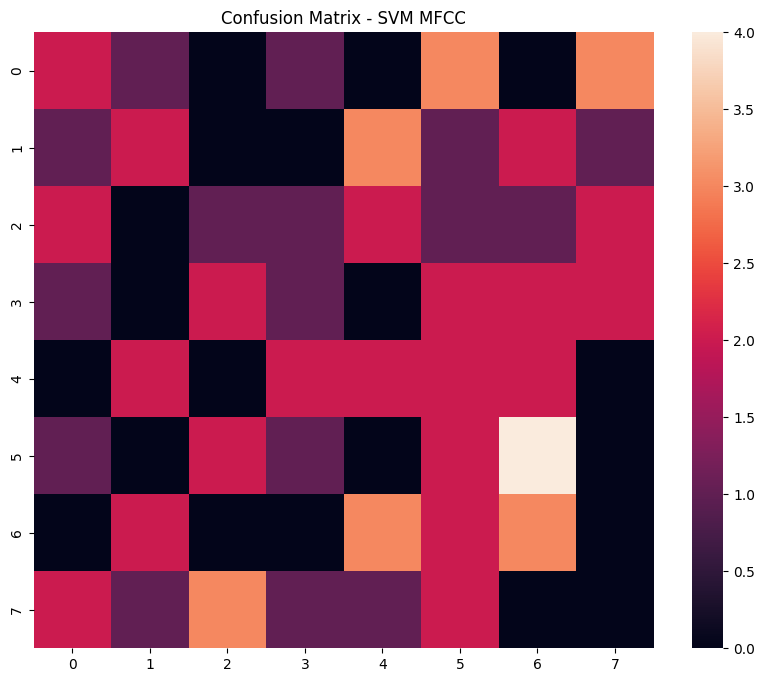

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = svm.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=False)
plt.title("Confusion Matrix - SVM MFCC")
plt.show()


# CNN deep learning pipeline

In [ ]:
import librosa
import librosa.display
import numpy as np
from tqdm import tqdm

mel_features = []
labels = []

for path, label in tqdm(zip(df.file_path, df.label), total=len(df)):
    y, sr = librosa.load(path, sr=22050)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    if mel_db.shape[1] < 300:
        pad = 300 - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0,0),(0,pad)), mode='constant')
    else:
        mel_db = mel_db[:, :300]

    mel_db = (mel_db - np.mean(mel_db)) / (np.std(mel_db) + 1e-6)

    mel_features.append(mel_db)
    labels.append(label)

mel_features = np.array(mel_features)
labels = np.array(labels)

print("Mel features shape:", mel_features.shape)
print("Labels shape:", labels.shape)


100%|██████████| 400/400 [00:34<00:00, 11.61it/s]


Mel features shape: (400, 128, 300)
Labels shape: (400,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(labels)

X_train, X_test, y_train, y_test = train_test_split(
    mel_features, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# CNN expects (samples, height, width, channel)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape, X_test.shape)


(320, 128, 300, 1) (80, 128, 300, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128, 300, 1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(len(np.unique(y_encoded)), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 298, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 149, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 147, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 73, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 73, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 73, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 36, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 69120)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    17,694,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,790,216 (67.86 MB)

 Trainable params: 17,789,960 (67.86 MB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_test, y_test)
)


Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.0886 - loss: 16.2586 - val_accuracy: 0.1625 - val_loss: 2.6943
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.2431 - loss: 2.1351 - val_accuracy: 0.1250 - val_loss: 2.8625
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.2901 - loss: 1.8308 - val_accuracy: 0.2000 - val_loss: 2.1219
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.3448 - loss: 1.6863 - val_accuracy: 0.2250 - val_loss: 2.0528
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.3949 - loss: 1.4966 - val_accuracy: 0.2125 - val_loss: 2.0435
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.4210 - loss: 1.4043 - val_accuracy: 0.2000 - val_loss: 2.0928
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.5152 - loss: 1.4455 - val_accuracy: 0.2875 - val_loss: 2.0375
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.5289 - loss: 1.1969 - val_accuracy: 0.1750 - val_loss

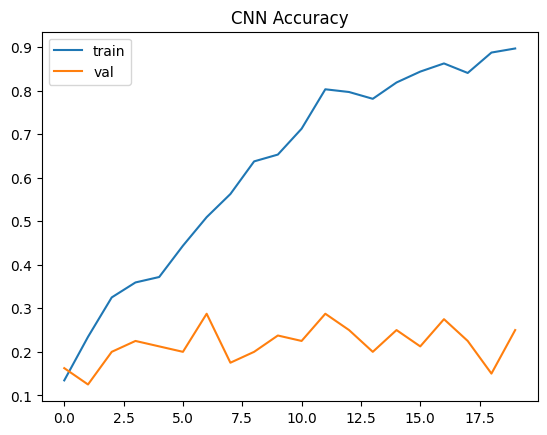

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])
Best Validation Accuracy: 0.2874999940395355


In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("CNN Accuracy")
plt.legend(['train','val'])
plt.show()

print(history.history.keys())
best_val_acc = max(history.history['val_accuracy'])
print("Best Validation Accuracy:", best_val_acc)

